### Belebele Few-Shot Shot-Count Study
### English (high-resource) vs Sinhala (low-resource)

In [ ]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

!pip install datasets transformers accelerate bitsandbytes sentencepiece pandas matplotlib tqdm --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 15.2 MB/s eta 0:00:00


In [ ]:
import os
import random
import time
import torch
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, BitsAndBytesConfig

In [ ]:
MODEL_NAME = "bigscience/mt0-xl"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto",
)
print("Model loaded.")

config.json:   0%|          | 0.00/797 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/430 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (3 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Model loaded.


In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("Model device map:", model.hf_device_map if hasattr(model, "hf_device_map") else "no device map found")

CUDA available: True
Model device map: no device map found


In [ ]:
print("Model parameter device:", next(model.parameters()).device)

Model parameter device: cuda:0


In [ ]:
del model
import gc
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    device_map={"": 0},   # force everything onto GPU 0
)
print("Model parameter device:", next(model.parameters()).device)

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Model parameter device: cuda:0


In [ ]:
CONFIG = {
    "model": "mt0-xl-4bit",
    "languages": {"English": "eng_Latn", "Sinhala": "sin_Sinh"},
    "shot_counts": [0, 1, 2, 4, 8],   # dropped 16 — GPU memory limit at long prompts
    "n_exemplar_pool": 30,
    "n_test_samples": 60,
    "n_seeds": 2,
    "random_seed_base": 42,
    "sleep_between_calls": 0,
    "output_dir": "results",
}
os.makedirs(CONFIG["output_dir"], exist_ok=True)

In [ ]:
def load_and_split(lang_code: str, seed: int):
    ds = load_dataset("facebook/belebele", lang_code, split="test")
    ds = ds.shuffle(seed=seed)
    exemplar_pool = ds.select(range(CONFIG["n_exemplar_pool"]))
    remaining = ds.select(range(
        CONFIG["n_exemplar_pool"],
        CONFIG["n_exemplar_pool"] + CONFIG["n_test_samples"]
    ))
    return exemplar_pool, remaining

In [ ]:
LETTERS = ["A", "B", "C", "D"]

def format_question_block(row, show_answer: bool):
    options = [row["mc_answer1"], row["mc_answer2"], row["mc_answer3"], row["mc_answer4"]]
    block = f"Passage: {row['flores_passage']}\n"
    block += f"Question: {row['question']}\n"
    for letter, opt in zip(LETTERS, options):
        block += f"{letter}. {opt}\n"
    if show_answer:
        correct_letter = LETTERS[int(row["correct_answer_num"]) - 1]
        block += f"Answer: {correct_letter}\n"
    else:
        block += "Answer:"
    return block

def build_prompt(exemplars, target_row):
    parts = [format_question_block(ex, show_answer=True) for ex in exemplars]
    parts.append(format_question_block(target_row, show_answer=False))
    instructions = (
        "Answer each multiple-choice reading comprehension question "
        "using only the passage provided. Respond with a single "
        "letter (A, B, C, or D) and nothing else."
    )
    return instructions + "\n\n" + "\n\n".join(parts)

In [ ]:
def sample_exemplars(exemplar_pool, k, seed):
    rng = random.Random(seed)
    if k == 0:
        return []
    indices = rng.sample(range(len(exemplar_pool)), k)
    return [exemplar_pool[i] for i in indices]

In [ ]:
tokenizer.truncation_side = "left"   # if truncation is unavoidable, cut the oldest exemplars first — never the target question, which is always last

def call_llm(prompt: str) -> str:
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=5120).to(model.device)
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=5,
            do_sample=False,
        )
    return tokenizer.decode(output_ids[0], skip_special_tokens=True).strip()

def parse_prediction(raw_output: str):
    for letter in LETTERS:
        if letter in raw_output.upper():
            return letter
    return None

In [ ]:
test_ds = load_dataset("facebook/belebele", "sin_Sinh", split="test")
sample_exemplars_for_timing = [test_ds[i] for i in range(8)]
target = test_ds[8]
test_prompt = build_prompt(sample_exemplars_for_timing, target)

start = time.time()
_ = call_llm(test_prompt)
elapsed = time.time() - start

total_calls = len(CONFIG["languages"]) * len(CONFIG["shot_counts"]) * CONFIG["n_seeds"] * CONFIG["n_test_samples"]
print(f"One 8-shot call took {elapsed:.2f} seconds")
print(f"Total calls planned: {total_calls}")
print(f"Estimated total run time: {elapsed * total_calls / 60:.1f} minutes")

README.md:   0%|          | 0.00/25.5k [00:00<?, ?B/s]

sin_Sinh.jsonl:   0%|          | 0.00/3.26M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/900 [00:00<?, ? examples/s]

One 8-shot call took 5.52 seconds
Total calls planned: 1200
Estimated total run time: 110.5 minutes


In [ ]:
def run_experiment():
    all_results = []
    for lang_name, lang_code in CONFIG["languages"].items():
        print(f"\n=== Language: {lang_name} ({lang_code}) ===")
        exemplar_pool, test_pool = load_and_split(lang_code, seed=CONFIG["random_seed_base"])

        for shot_count in CONFIG["shot_counts"]:
            for seed_offset in range(CONFIG["n_seeds"]):
                seed = CONFIG["random_seed_base"] + seed_offset
                exemplars = sample_exemplars(exemplar_pool, shot_count, seed)

                correct, total = 0, 0
                for row in tqdm(test_pool, desc=f"{lang_name} | shots={shot_count} | seed={seed}"):
                    prompt = build_prompt(exemplars, row)
                    try:
                        raw = call_llm(prompt)
                    except Exception as e:
                        print(f"Generation error on row: {type(e).__name__}: {e}")
                        torch.cuda.empty_cache()
                        continue

                    pred = parse_prediction(raw)
                    gold = LETTERS[int(row["correct_answer_num"]) - 1]
                    total += 1
                    if pred == gold:
                        correct += 1

                accuracy = correct / total if total > 0 else 0.0
                torch.cuda.empty_cache()
                all_results.append({
                    "language": lang_name, "shot_count": shot_count,
                    "seed": seed, "accuracy": accuracy, "n_scored": total,
                })
                pd.DataFrame(all_results).to_csv(f"{CONFIG['output_dir']}/raw_results.csv", index=False)

    return pd.DataFrame(all_results)

In [ ]:
exemplar_pool, test_pool = load_and_split(CONFIG["languages"]["Sinhala"], seed=CONFIG["random_seed_base"])
exemplars = sample_exemplars(exemplar_pool, 16, 42)
prompt = build_prompt(exemplars, test_pool[0])

try:
    raw = call_llm(prompt)
    print("Success:", raw)
except Exception as e:
    print(f"{type(e).__name__}: {e}")

OutOfMemoryError: CUDA out of memory. Tried to allocate 2.71 GiB. GPU 0 has a total capacity of 14.56 GiB of which 1.88 GiB is free. Including non-PyTorch memory, this process has 12.68 GiB memory in use. Of the allocated memory 12.51 GiB is allocated by PyTorch, and 47.77 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)


In [ ]:
def aggregate_results(df):
    agg = df.groupby(["language", "shot_count"])["accuracy"].agg(["mean", "std"]).reset_index()
    agg.to_csv(f"{CONFIG['output_dir']}/aggregated_results.csv", index=False)
    return agg

def plot_results(agg):
    plt.figure(figsize=(8, 5))
    for lang in agg["language"].unique():
        sub = agg[agg["language"] == lang].sort_values("shot_count")
        plt.errorbar(sub["shot_count"], sub["mean"], yerr=sub["std"].fillna(0),
                      marker="o", capsize=4, label=lang)
    plt.xlabel("Number of shots (k)")
    plt.ylabel("Accuracy")
    plt.title("Belebele accuracy vs. shot count: English vs. Sinhala")
    plt.xscale("symlog", base=2)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/shot_count_curve.png", dpi=300)
    plt.show()

def find_elbow(agg, threshold=0.01):
    elbows = {}
    for lang in agg["language"].unique():
        sub = agg[agg["language"] == lang].sort_values("shot_count").reset_index(drop=True)
        elbow_k = sub["shot_count"].iloc[-1]
        for i in range(1, len(sub)):
            if sub["mean"].iloc[i] - sub["mean"].iloc[i - 1] < threshold:
                elbow_k = sub["shot_count"].iloc[i - 1]
                break
        elbows[lang] = elbow_k
    return elbows


=== Language: English (eng_Latn) ===


eng_Latn.jsonl:   0%|          | 0.00/836k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/900 [00:00<?, ? examples/s]

English | shots=0 | seed=42: 100%|██████████| 60/60 [00:16<00:00,  3.72it/s]
English | shots=0 | seed=43: 100%|██████████| 60/60 [00:16<00:00,  3.65it/s]
English | shots=1 | seed=42: 100%|██████████| 60/60 [00:21<00:00,  2.73it/s]
English | shots=1 | seed=43: 100%|██████████| 60/60 [00:21<00:00,  2.83it/s]
English | shots=2 | seed=42: 100%|██████████| 60/60 [00:27<00:00,  2.15it/s]
English | shots=2 | seed=43: 100%|██████████| 60/60 [00:25<00:00,  2.31it/s]
English | shots=4 | seed=42: 100%|██████████| 60/60 [00:48<00:00,  1.24it/s]
English | shots=4 | seed=43: 100%|██████████| 60/60 [00:47<00:00,  1.26it/s]
English | shots=8 | seed=42: 100%|██████████| 60/60 [01:38<00:00,  1.65s/it]
English | shots=8 | seed=43: 100%|██████████| 60/60 [01:46<00:00,  1.77s/it]



=== Language: Sinhala (sin_Sinh) ===


Sinhala | shots=0 | seed=42: 100%|██████████| 60/60 [00:19<00:00,  3.01it/s]
Sinhala | shots=0 | seed=43: 100%|██████████| 60/60 [00:20<00:00,  2.96it/s]
Sinhala | shots=1 | seed=42: 100%|██████████| 60/60 [00:30<00:00,  1.99it/s]
Sinhala | shots=1 | seed=43: 100%|██████████| 60/60 [00:27<00:00,  2.16it/s]
Sinhala | shots=2 | seed=42: 100%|██████████| 60/60 [00:42<00:00,  1.41it/s]
Sinhala | shots=2 | seed=43: 100%|██████████| 60/60 [00:36<00:00,  1.63it/s]
Sinhala | shots=4 | seed=42: 100%|██████████| 60/60 [01:26<00:00,  1.43s/it]
Sinhala | shots=4 | seed=43: 100%|██████████| 60/60 [01:19<00:00,  1.33s/it]
Sinhala | shots=8 | seed=42: 100%|██████████| 60/60 [03:19<00:00,  3.33s/it]
Sinhala | shots=8 | seed=43: 100%|██████████| 60/60 [03:38<00:00,  3.64s/it]


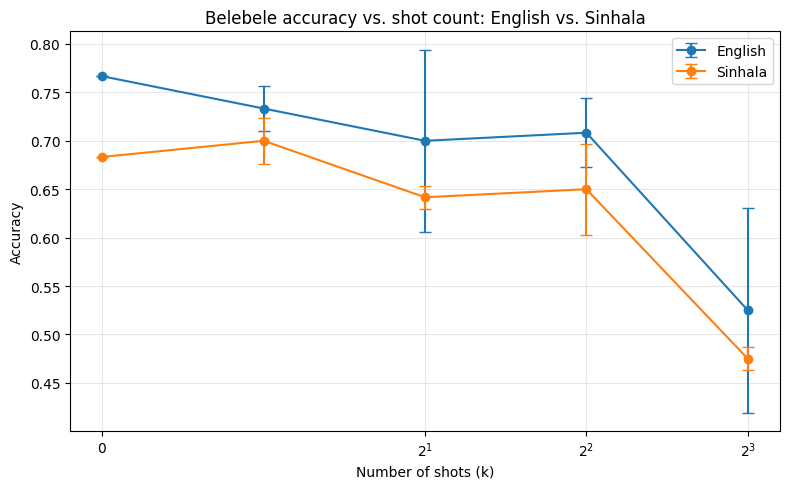

English: plateaus around k = 0
Sinhala: plateaus around k = 1


In [ ]:
raw_df = run_experiment()
agg_df = aggregate_results(raw_df)
plot_results(agg_df)
elbows = find_elbow(agg_df)
for lang, k in elbows.items():
    print(f"{lang}: plateaus around k = {k}")

In [ ]:
exemplar_pool, test_pool = load_and_split(CONFIG["languages"]["Sinhala"], seed=CONFIG["random_seed_base"])

for k in [0, 1, 2, 4, 8, 16]:
    exemplars = sample_exemplars(exemplar_pool, k, 42)
    prompt = build_prompt(exemplars, test_pool[0])
    n_tokens = len(tokenizer(prompt)["input_ids"])
    print(f"k={k}: {n_tokens} tokens")

k=0: 401 tokens
k=1: 677 tokens
k=2: 914 tokens
k=4: 1544 tokens
k=8: 2582 tokens
k=16: 4771 tokens


In [ ]:
df = pd.read_csv("results/raw_results.csv")
print(df[df["shot_count"] == 8])

   language  shot_count  seed  accuracy  n_scored
8   English           8    42  0.600000        60
9   English           8    43  0.450000        60
18  Sinhala           8    42  0.466667        60
19  Sinhala           8    43  0.483333        60


In [ ]:
# Follow-up: k=16 only, smaller sample to fit GPU memory
k16_results = []

for lang_name, lang_code in CONFIG["languages"].items():
    exemplar_pool, test_pool_full = load_and_split(lang_code, seed=CONFIG["random_seed_base"])
    test_pool = test_pool_full.select(range(20))   # smaller sample just for this follow-up

    for seed_offset in range(CONFIG["n_seeds"]):
        seed = CONFIG["random_seed_base"] + seed_offset
        exemplars = sample_exemplars(exemplar_pool, 16, seed)

        correct, total = 0, 0
        for row in tqdm(test_pool, desc=f"{lang_name} | shots=16 | seed={seed}"):
            prompt = build_prompt(exemplars, row)
            try:
                raw = call_llm(prompt)
            except Exception as e:
                print(f"Generation error on row: {type(e).__name__}: {e}")
                torch.cuda.empty_cache()
                continue

            pred = parse_prediction(raw)
            gold = LETTERS[int(row["correct_answer_num"]) - 1]
            total += 1
            if pred == gold:
                correct += 1

        accuracy = correct / total if total > 0 else 0.0
        torch.cuda.empty_cache()
        k16_results.append({
            "language": lang_name, "shot_count": 16,
            "seed": seed, "accuracy": accuracy, "n_scored": total,
        })

k16_df = pd.DataFrame(k16_results)
print(k16_df)
k16_df.to_csv(f"{CONFIG['output_dir']}/k16_followup.csv", index=False)

English | shots=16 | seed=42: 100%|██████████| 20/20 [01:30<00:00,  4.53s/it]
English | shots=16 | seed=43: 100%|██████████| 20/20 [01:37<00:00,  4.88s/it]
Sinhala | shots=16 | seed=42:   5%|▌         | 1/20 [00:00<00:10,  1.82it/s]

Generation error on row: OutOfMemoryError: CUDA out of memory. Tried to allocate 2.71 GiB. GPU 0 has a total capacity of 14.56 GiB of which 1.88 GiB is free. Including non-PyTorch memory, this process has 12.68 GiB memory in use. Of the allocated memory 12.51 GiB is allocated by PyTorch, and 47.77 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)


Sinhala | shots=16 | seed=42:  10%|█         | 2/20 [00:01<00:09,  1.98it/s]

Generation error on row: OutOfMemoryError: CUDA out of memory. Tried to allocate 2.59 GiB. GPU 0 has a total capacity of 14.56 GiB of which 2.12 GiB is free. Including non-PyTorch memory, this process has 12.45 GiB memory in use. Of the allocated memory 12.25 GiB is allocated by PyTorch, and 70.88 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)


Sinhala | shots=16 | seed=42:  15%|█▌        | 3/20 [00:01<00:08,  2.04it/s]

Generation error on row: OutOfMemoryError: CUDA out of memory. Tried to allocate 2.71 GiB. GPU 0 has a total capacity of 14.56 GiB of which 1.86 GiB is free. Including non-PyTorch memory, this process has 12.70 GiB memory in use. Of the allocated memory 12.51 GiB is allocated by PyTorch, and 65.40 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)


... (70 outputs left out)

Sinhala | shots=16 | seed=43:  95%|█████████▌| 19/20 [00:09<00:00,  2.10it/s]

Generation error on row: OutOfMemoryError: CUDA out of memory. Tried to allocate 2.69 GiB. GPU 0 has a total capacity of 14.56 GiB of which 1.90 GiB is free. Including non-PyTorch memory, this process has 12.66 GiB memory in use. Of the allocated memory 12.46 GiB is allocated by PyTorch, and 77.57 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)


Sinhala | shots=16 | seed=43: 100%|██████████| 20/20 [00:09<00:00,  2.08it/s]

Generation error on row: OutOfMemoryError: CUDA out of memory. Tried to allocate 2.81 GiB. GPU 0 has a total capacity of 14.56 GiB of which 1.67 GiB is free. Including non-PyTorch memory, this process has 12.89 GiB memory in use. Of the allocated memory 12.71 GiB is allocated by PyTorch, and 64.01 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)
  language  shot_count  seed  accuracy  n_scored
0  English          16    42      0.60        20
1  English          16    43      0.65        20
2  Sinhala          16    42      0.00         0
3  Sinhala          16    43      0.00         0


In [ ]:
# Qualitative error analysis: capture raw outputs at k=0 vs k=8
error_analysis = []

for lang_name, lang_code in CONFIG["languages"].items():
    exemplar_pool, test_pool_full = load_and_split(lang_code, seed=CONFIG["random_seed_base"])
    test_pool = test_pool_full.select(range(20))   # smaller sample, just for inspection

    for shot_count in [0, 8]:
        exemplars = sample_exemplars(exemplar_pool, shot_count, CONFIG["random_seed_base"])

        for row in tqdm(test_pool, desc=f"{lang_name} | shots={shot_count}"):
            prompt = build_prompt(exemplars, row)
            try:
                raw = call_llm(prompt)
            except Exception as e:
                raw = f"[ERROR: {e}]"

            pred = parse_prediction(raw)
            gold = LETTERS[int(row["correct_answer_num"]) - 1]

            error_analysis.append({
                "language": lang_name,
                "shot_count": shot_count,
                "question": row["question"][:80],   # truncate for readability
                "raw_output": raw,
                "parsed_pred": pred,
                "gold_answer": gold,
                "correct": pred == gold,
            })
        torch.cuda.empty_cache()

error_df = pd.DataFrame(error_analysis)
error_df.to_csv(f"{CONFIG['output_dir']}/error_analysis.csv", index=False)

# Show only the wrong answers, grouped for easy reading
wrong = error_df[~error_df["correct"]]
print(f"Total wrong: {len(wrong)} out of {len(error_df)}\n")
for (lang, shots), group in wrong.groupby(["language", "shot_count"]):
    print(f"\n=== {lang} | shots={shots} | {len(group)} wrong ===")
    print(group[["question", "raw_output", "parsed_pred", "gold_answer"]].to_string(index=False))

English | shots=0: 100%|██████████| 20/20 [00:05<00:00,  3.47it/s]
English | shots=8: 100%|██████████| 20/20 [00:32<00:00,  1.65s/it]
Sinhala | shots=0: 100%|██████████| 20/20 [00:06<00:00,  3.03it/s]
Sinhala | shots=8: 100%|██████████| 20/20 [01:06<00:00,  3.34s/it]

Total wrong: 26 out of 80


=== English | shots=0 | 4 wrong ===
                                                                        question raw_output parsed_pred gold_answer
Which line of work mentioned in the passage employs the least number of Venezuel          A           A           C
According to the passage, which of the following statements accurately describes          D           D           B
Which of the following is not mentioned as a possible name for the Bronze Age Ci          A           A           C
According to the passage, which of the following is an accurate statement regard          A           A           D

=== English | shots=8 | 6 wrong ===
                                                                        question raw_output parsed_pred gold_answer
                                     Where were Colonel Stark’s troops situated?          C           C           A
Based on the information given in the passage, which of the following sports won       

In [ ]:
# Check: how often was "C" the correct answer among the 8 exemplars shown?
exemplar_pool, _ = load_and_split(CONFIG["languages"]["English"], seed=CONFIG["random_seed_base"])
exemplars_k8 = sample_exemplars(exemplar_pool, 8, CONFIG["random_seed_base"])
exemplar_letters = [LETTERS[int(ex["correct_answer_num"]) - 1] for ex in exemplars_k8]
print("Letters shown as correct answers in the 8 exemplars:", exemplar_letters)


Letters shown as correct answers in the 8 exemplars: ['B', 'B', 'A', 'C', 'A', 'D', 'B', 'A']


In [ ]:
k8_all = error_df[error_df["shot_count"] == 8]
print(k8_all["parsed_pred"].value_counts())
print("\nCompare to gold distribution:")
print(k8_all["gold_answer"].value_counts())

parsed_pred
C    21
D     9
B     5
A     5
Name: count, dtype: int64

Compare to gold distribution:
gold_answer
D    14
C    10
B     8
A     8
Name: count, dtype: int64


In [ ]:
# Extend qualitative capture to include k=4, so we can see the bias trend across shot counts
error_analysis_k4 = []

for lang_name, lang_code in CONFIG["languages"].items():
    exemplar_pool, test_pool_full = load_and_split(lang_code, seed=CONFIG["random_seed_base"])
    test_pool = test_pool_full.select(range(20))

    exemplars = sample_exemplars(exemplar_pool, 4, CONFIG["random_seed_base"])

    for row in tqdm(test_pool, desc=f"{lang_name} | shots=4"):
        prompt = build_prompt(exemplars, row)
        try:
            raw = call_llm(prompt)
        except Exception as e:
            raw = f"[ERROR: {e}]"

        pred = parse_prediction(raw)
        gold = LETTERS[int(row["correct_answer_num"]) - 1]

        error_analysis_k4.append({
            "language": lang_name, "shot_count": 4,
            "raw_output": raw, "parsed_pred": pred, "gold_answer": gold,
            "correct": pred == gold,
        })
    torch.cuda.empty_cache()

k4_df = pd.DataFrame(error_analysis_k4)

# Combine with existing k=0 and k=8 data (from error_df) for a full comparison across shot counts
combined = pd.concat([error_df, k4_df], ignore_index=True)

print("Predicted-letter distribution by shot count:\n")
for shots in [0, 4, 8]:
    subset = combined[combined["shot_count"] == shots]
    print(f"--- k={shots} ---")
    print(subset["parsed_pred"].value_counts())
    print()

English | shots=4: 100%|██████████| 20/20 [00:16<00:00,  1.24it/s]
Sinhala | shots=4: 100%|██████████| 20/20 [00:28<00:00,  1.44s/it]

Predicted-letter distribution by shot count:

--- k=0 ---
parsed_pred
A    15
D    13
B     6
C     6
Name: count, dtype: int64

--- k=4 ---
parsed_pred
D    14
A    12
C    10
B     4
Name: count, dtype: int64

--- k=8 ---
parsed_pred
C    21
D     9
B     5
A     5
Name: count, dtype: int64



In [ ]:
# More seeds at k=8, to check the "C" bias holds across different exemplar draws
extra_seeds = [44, 45, 46]
k8_extra_results = []

for lang_name, lang_code in CONFIG["languages"].items():
    exemplar_pool, test_pool_full = load_and_split(lang_code, seed=CONFIG["random_seed_base"])
    test_pool = test_pool_full.select(range(20))   # match the sample size used in the earlier qualitative check

    for seed in extra_seeds:
        exemplars = sample_exemplars(exemplar_pool, 8, seed)

        for row in tqdm(test_pool, desc=f"{lang_name} | shots=8 | seed={seed}"):
            prompt = build_prompt(exemplars, row)
            try:
                raw = call_llm(prompt)
            except Exception as e:
                raw = f"[ERROR: {e}]"

            pred = parse_prediction(raw)
            gold = LETTERS[int(row["correct_answer_num"]) - 1]

            k8_extra_results.append({
                "language": lang_name, "shot_count": 8, "seed": seed,
                "parsed_pred": pred, "gold_answer": gold, "correct": pred == gold,
            })
        torch.cuda.empty_cache()

k8_extra_df = pd.DataFrame(k8_extra_results)
k8_extra_df.to_csv(f"{CONFIG['output_dir']}/k8_extra_seeds.csv", index=False)

# Combine with the original k=8 predictions captured earlier (from error_df)
k8_original = error_df[error_df["shot_count"] == 8][["language", "shot_count", "parsed_pred", "gold_answer", "correct"]].copy()
k8_original["seed"] = "original"   # seeds 42/43 combined, since error_df didn't track seed separately

k8_all_seeds = pd.concat([k8_original, k8_extra_df], ignore_index=True)

print("=== Predicted-letter distribution at k=8, across ALL seeds combined ===")
print(k8_all_seeds["parsed_pred"].value_counts())
print(f"\nTotal predictions: {len(k8_all_seeds)}")

print("\n=== True (gold) letter distribution, for comparison ===")
print(k8_all_seeds["gold_answer"].value_counts())

# Per-seed breakdown, to see if EVERY seed shows the C bias or just some
print("\n=== C-selection rate, per seed ===")
for seed_val, group in k8_all_seeds.groupby("seed"):
    c_rate = (group["parsed_pred"] == "C").mean()
    print(f"seed={seed_val}: predicted C in {c_rate:.1%} of {len(group)} predictions")

English | shots=8 | seed=44: 100%|██████████| 20/20 [00:33<00:00,  1.66s/it]
English | shots=8 | seed=45: 100%|██████████| 20/20 [00:29<00:00,  1.46s/it]
English | shots=8 | seed=46: 100%|██████████| 20/20 [00:28<00:00,  1.43s/it]
Sinhala | shots=8 | seed=44: 100%|██████████| 20/20 [01:03<00:00,  3.18s/it]
Sinhala | shots=8 | seed=45: 100%|██████████| 20/20 [00:55<00:00,  2.79s/it]
Sinhala | shots=8 | seed=46: 100%|██████████| 20/20 [00:59<00:00,  2.96s/it]

=== Predicted-letter distribution at k=8, across ALL seeds combined ===
parsed_pred
C    80
D    31
A    26
B    23
Name: count, dtype: int64

Total predictions: 160

=== True (gold) letter distribution, for comparison ===
gold_answer
D    56
C    40
B    32
A    32
Name: count, dtype: int64

=== C-selection rate, per seed ===
seed=44: predicted C in 47.5% of 40 predictions
seed=45: predicted C in 50.0% of 40 predictions
seed=46: predicted C in 50.0% of 40 predictions
seed=original: predicted C in 52.5% of 40 predictions


In [ ]:
# Manual spot-check: read individual predictions yourself to confirm the pipeline is scoring correctly
def spot_check(lang_key, n_examples=3, shot_count=0):
    lang_code = CONFIG["languages"][lang_key]
    exemplar_pool, test_pool = load_and_split(lang_code, seed=CONFIG["random_seed_base"])
    exemplars = sample_exemplars(exemplar_pool, shot_count, CONFIG["random_seed_base"])

    for row in test_pool.select(range(n_examples)):
        prompt = build_prompt(exemplars, row)
        raw = call_llm(prompt)
        pred = parse_prediction(raw)
        gold = LETTERS[int(row["correct_answer_num"]) - 1]

        print(f"LANGUAGE: {lang_key} | SHOTS: {shot_count}")
        print(f"PASSAGE: {row['flores_passage'][:400]}...")
        print(f"QUESTION: {row['question']}")
        options = [row["mc_answer1"], row["mc_answer2"], row["mc_answer3"], row["mc_answer4"]]
        for letter, opt in zip(LETTERS, options):
            marker = " <-- GOLD" if letter == gold else ""
            print(f"  {letter}. {opt}{marker}")
        print(f"MODEL RAW OUTPUT: '{raw}'")
        print(f"PARSED PREDICTION: {pred}")
        print(f"RESULT: {'CORRECT ✓' if pred == gold else 'WRONG ✗'}")
        print("=" * 100)

# Check a few English examples at zero-shot (easiest to read/verify yourself)
spot_check("English", n_examples=3, shot_count=0)

LANGUAGE: English | SHOTS: 0
PASSAGE: The Colonists, seeing this activity, had also called for reinforcements. Troops reinforcing the forward positions included the 1st and 3rd New Hampshire regiments of 200 men, under Colonels John Stark and James Reed (both later became generals). Stark's men took positions along the fence on the north end of the Colonist's position. When low tide opened a gap along the Mystic River along the northe...
QUESTION: Where were Colonel Stark’s troops situated?
  A. On the north end, along the fence <-- GOLD
  B. On a beach at the water’s edge
  C. Along the northeast of the peninsula
  D. In front of the fence
MODEL RAW OUTPUT: 'A'
PARSED PREDICTION: A
RESULT: CORRECT ✓
LANGUAGE: English | SHOTS: 0
PASSAGE: Italy's national football, along with German national football team is the second most successful team in the world and were the FIFA World Cup champions in 2006. Popular sports include football, basketball, volleyball, water-polo, fencing, rugby, cycl

In [ ]:
spot_check("Sinhala", n_examples=3, shot_count=0)

LANGUAGE: Sinhala | SHOTS: 0
PASSAGE: මෙම ක්‍රියාකාරකම දුටු යටත් විජිතවාදීන් ද සිය හමුදා ශක්තිමත් කිරීම් ඉල්ලා සිටියහ. ඉදිරිපස ස්ථානවලට ඇතුළු වූ භටයන් අතර, (පසුව ජනරාල්වරුන් බවට පත් වූ) කර්නල්වරුන් වූ ජෝන් ස්ටාර්ක් සහ ජේම්ස් රීඩ් යටතේ, සෙබළුන් 200 දෙනෙකින් යුත් 1 වෙනි සහ 3 වෙනි නිව් හෑම්ප්ෂයර් රෙජිමේන්තු විය. ස්ටාර්ක්ගේ මිනිසුන් යටත් ජනපදවැසියන්ගේ ස්ථානයේ උතුරු කෙළවරේ මායිම දිගේ ස්ථානගත විය. බාදිය මගින් අර්ධද්වීපයේ ඊසාන දෙසින් මිස්ටික...
QUESTION: කර්නල් ස්ටාර්ක්ගේ සෙබළු සිටියේ කොහේද?
  A. උතුරු කෙළවර, මායිම දිගේ <-- GOLD
  B. වෙරළ තීරයක ජල අද්දර
  C. අර්ධද්වීපයේ ඊසාන දිගින්
  D. වැටට ඉදිරියෙන්
MODEL RAW OUTPUT: 'A'
PARSED PREDICTION: A
RESULT: CORRECT ✓
LANGUAGE: Sinhala | SHOTS: 0
PASSAGE: ඉතාලි ජාතික පාපන්දු කණ්ඩායම, ජර්මානු ජාතික පාපන්දු කණ්ඩායම සමඟ, ලොව දෙවන සාර්ථකතම කණ්ඩායම වන අතර 2006 දී FIFA ලෝක කුසලාන ශූරතාවය දිනා ගත්තේය. පාපන්දු, පැසිපන්දු, දැල්පන්දු, ජල පෝලෝ, කඩු හරඹ, රග්බි, බයිසිකල් ධාවනය, අයිස් හොකී, රෝලර් හොකී සහ F1 මෝටර් රථ ධාවනය ජනප්‍රිය ක්‍රීඩාවන්ට ඇතුලත් වේ. ඉතාලි ජාත

In [ ]:
spot_check("English", n_examples=3, shot_count=8)

LANGUAGE: English | SHOTS: 8
PASSAGE: The Colonists, seeing this activity, had also called for reinforcements. Troops reinforcing the forward positions included the 1st and 3rd New Hampshire regiments of 200 men, under Colonels John Stark and James Reed (both later became generals). Stark's men took positions along the fence on the north end of the Colonist's position. When low tide opened a gap along the Mystic River along the northe...
QUESTION: Where were Colonel Stark’s troops situated?
  A. On the north end, along the fence <-- GOLD
  B. On a beach at the water’s edge
  C. Along the northeast of the peninsula
  D. In front of the fence
MODEL RAW OUTPUT: 'C'
PARSED PREDICTION: C
RESULT: WRONG ✗
LANGUAGE: English | SHOTS: 8
PASSAGE: Italy's national football, along with German national football team is the second most successful team in the world and were the FIFA World Cup champions in 2006. Popular sports include football, basketball, volleyball, water-polo, fencing, rugby, cyclin

In [ ]:
spot_check("Sinhala", n_examples=3, shot_count=8)

LANGUAGE: Sinhala | SHOTS: 8
PASSAGE: මෙම ක්‍රියාකාරකම දුටු යටත් විජිතවාදීන් ද සිය හමුදා ශක්තිමත් කිරීම් ඉල්ලා සිටියහ. ඉදිරිපස ස්ථානවලට ඇතුළු වූ භටයන් අතර, (පසුව ජනරාල්වරුන් බවට පත් වූ) කර්නල්වරුන් වූ ජෝන් ස්ටාර්ක් සහ ජේම්ස් රීඩ් යටතේ, සෙබළුන් 200 දෙනෙකින් යුත් 1 වෙනි සහ 3 වෙනි නිව් හෑම්ප්ෂයර් රෙජිමේන්තු විය. ස්ටාර්ක්ගේ මිනිසුන් යටත් ජනපදවැසියන්ගේ ස්ථානයේ උතුරු කෙළවරේ මායිම දිගේ ස්ථානගත විය. බාදිය මගින් අර්ධද්වීපයේ ඊසාන දෙසින් මිස්ටික...
QUESTION: කර්නල් ස්ටාර්ක්ගේ සෙබළු සිටියේ කොහේද?
  A. උතුරු කෙළවර, මායිම දිගේ <-- GOLD
  B. වෙරළ තීරයක ජල අද්දර
  C. අර්ධද්වීපයේ ඊසාන දිගින්
  D. වැටට ඉදිරියෙන්
MODEL RAW OUTPUT: 'A'
PARSED PREDICTION: A
RESULT: CORRECT ✓
LANGUAGE: Sinhala | SHOTS: 8
PASSAGE: ඉතාලි ජාතික පාපන්දු කණ්ඩායම, ජර්මානු ජාතික පාපන්දු කණ්ඩායම සමඟ, ලොව දෙවන සාර්ථකතම කණ්ඩායම වන අතර 2006 දී FIFA ලෝක කුසලාන ශූරතාවය දිනා ගත්තේය. පාපන්දු, පැසිපන්දු, දැල්පන්දු, ජල පෝලෝ, කඩු හරඹ, රග්බි, බයිසිකල් ධාවනය, අයිස් හොකී, රෝලර් හොකී සහ F1 මෝටර් රථ ධාවනය ජනප්‍රිය ක්‍රීඩාවන්ට ඇතුලත් වේ. ඉතාලි ජාත

In [ ]:
# Relabel A/B/C/D as W/X/Y/Z, same positions, same content — isolates label vs. position
ALT_LETTERS = ["W", "X", "Y", "Z"]

def format_question_block_relabeled(row, show_answer: bool):
    options = [row["mc_answer1"], row["mc_answer2"], row["mc_answer3"], row["mc_answer4"]]
    block = f"Passage: {row['flores_passage']}\n"
    block += f"Question: {row['question']}\n"
    for letter, opt in zip(ALT_LETTERS, options):
        block += f"{letter}. {opt}\n"
    if show_answer:
        correct_letter = ALT_LETTERS[int(row["correct_answer_num"]) - 1]
        block += f"Answer: {correct_letter}\n"
    else:
        block += "Answer:"
    return block

def build_prompt_relabeled(exemplars, target_row):
    parts = [format_question_block_relabeled(ex, show_answer=True) for ex in exemplars]
    parts.append(format_question_block_relabeled(target_row, show_answer=False))
    instructions = (
        "Answer each multiple-choice reading comprehension question "
        "using only the passage provided. Respond with a single "
        "letter (W, X, Y, or Z) and nothing else."
    )
    return instructions + "\n\n" + "\n\n".join(parts)

def parse_prediction_relabeled(raw_output: str):
    for letter in ALT_LETTERS:
        if letter in raw_output.upper():
            return letter
    return None

# Run at k=8, same setup as before
relabel_results = []
for lang_name, lang_code in CONFIG["languages"].items():
    exemplar_pool, test_pool_full = load_and_split(lang_code, seed=CONFIG["random_seed_base"])
    test_pool = test_pool_full.select(range(20))
    exemplars = sample_exemplars(exemplar_pool, 8, CONFIG["random_seed_base"])

    for row in tqdm(test_pool, desc=f"{lang_name} | relabeled k=8"):
        prompt = build_prompt_relabeled(exemplars, row)
        try:
            raw = call_llm(prompt)
        except Exception as e:
            raw = f"[ERROR: {e}]"
        pred = parse_prediction_relabeled(raw)
        relabel_results.append({"language": lang_name, "parsed_pred": pred})
    torch.cuda.empty_cache()

relabel_df = pd.DataFrame(relabel_results)
print(relabel_df["parsed_pred"].value_counts())

English | relabeled k=8: 100%|██████████| 20/20 [00:33<00:00,  1.68s/it]
Sinhala | relabeled k=8: 100%|██████████| 20/20 [01:05<00:00,  3.30s/it]

parsed_pred
W    18
Y    11
X     6
Z     3
Name: count, dtype: int64


In [ ]:
# Seed-replication of the relabeled (W/X/Y/Z) experiment at k=8
relabel_seeds = [42, 44, 45, 46]
relabel_results_full = []

for lang_name, lang_code in CONFIG["languages"].items():
    exemplar_pool, test_pool_full = load_and_split(lang_code, seed=CONFIG["random_seed_base"])
    test_pool = test_pool_full.select(range(20))

    for seed in relabel_seeds:
        exemplars = sample_exemplars(exemplar_pool, 8, seed)

        for row in tqdm(test_pool, desc=f"{lang_name} | relabeled k=8 | seed={seed}"):
            prompt = build_prompt_relabeled(exemplars, row)
            try:
                raw = call_llm(prompt)
            except Exception as e:
                raw = f"[ERROR: {e}]"

            pred = parse_prediction_relabeled(raw)
            relabel_results_full.append({
                "language": lang_name, "seed": seed, "parsed_pred": pred,
            })
        torch.cuda.empty_cache()

relabel_full_df = pd.DataFrame(relabel_results_full)
relabel_full_df.to_csv(f"{CONFIG['output_dir']}/relabel_seed_replication.csv", index=False)

print("=== Combined distribution across all 4 seeds ===")
print(relabel_full_df["parsed_pred"].value_counts())
print(f"\nTotal predictions: {len(relabel_full_df)}")

print("\n=== Per-seed breakdown — does 'W' dominance hold in EVERY seed? ===")
for seed_val, group in relabel_full_df.groupby("seed"):
    counts = group["parsed_pred"].value_counts()
    top_letter = counts.idxmax() if len(counts) > 0 else "N/A"
    top_rate = counts.max() / len(group) if len(group) > 0 else 0
    print(f"seed={seed_val}: dominant = '{top_letter}' at {top_rate:.1%} of {len(group)} predictions | full: {dict(counts)}")


English | relabeled k=8 | seed=42: 100%|██████████| 20/20 [00:33<00:00,  1.68s/it]
English | relabeled k=8 | seed=44: 100%|██████████| 20/20 [00:33<00:00,  1.65s/it]
English | relabeled k=8 | seed=45: 100%|██████████| 20/20 [00:28<00:00,  1.43s/it]
English | relabeled k=8 | seed=46: 100%|██████████| 20/20 [00:28<00:00,  1.42s/it]
Sinhala | relabeled k=8 | seed=42: 100%|██████████| 20/20 [01:06<00:00,  3.31s/it]
Sinhala | relabeled k=8 | seed=44: 100%|██████████| 20/20 [01:03<00:00,  3.18s/it]
Sinhala | relabeled k=8 | seed=45: 100%|██████████| 20/20 [00:57<00:00,  2.87s/it]
Sinhala | relabeled k=8 | seed=46: 100%|██████████| 20/20 [00:59<00:00,  2.98s/it]

=== Combined distribution across all 4 seeds ===
parsed_pred
W    71
Y    48
X    21
Z     8
Name: count, dtype: int64

Total predictions: 160

=== Per-seed breakdown — does 'W' dominance hold in EVERY seed? ===
seed=42: dominant = 'W' at 45.0% of 40 predictions | full: {'W': np.int64(18), 'Y': np.int64(11), 'X': np.int64(6), 'Z': np.int64(3)}
seed=44: dominant = 'W' at 50.0% of 40 predictions | full: {'W': np.int64(20), 'Y': np.int64(14), 'X': np.int64(2)}
seed=45: dominant = 'Y' at 37.5% of 40 predictions | full: {'Y': np.int64(15), 'W': np.int64(13), 'X': np.int64(6), 'Z': np.int64(3)}
seed=46: dominant = 'W' at 50.0% of 40 predictions | full: {'W': np.int64(20), 'Y': np.int64(8), 'X': np.int64(7), 'Z': np.int64(2)}


In [ ]:
# Pinpoint the threshold: test k=5, 6, 7 individually
threshold_results = []

for lang_name, lang_code in CONFIG["languages"].items():
    exemplar_pool, test_pool_full = load_and_split(lang_code, seed=CONFIG["random_seed_base"])
    test_pool = test_pool_full.select(range(20))

    for shot_count in [5, 6, 7]:
        exemplars = sample_exemplars(exemplar_pool, shot_count, CONFIG["random_seed_base"])

        correct, total = 0, 0
        letter_counts = {"A": 0, "B": 0, "C": 0, "D": 0, "None": 0}

        for row in tqdm(test_pool, desc=f"{lang_name} | shots={shot_count}"):
            prompt = build_prompt(exemplars, row)
            try:
                raw = call_llm(prompt)
            except Exception as e:
                raw = f"[ERROR: {e}]"

            pred = parse_prediction(raw)
            gold = LETTERS[int(row["correct_answer_num"]) - 1]

            total += 1
            if pred == gold:
                correct += 1
            letter_counts[pred if pred else "None"] += 1

        accuracy = correct / total if total > 0 else 0.0
        torch.cuda.empty_cache()

        threshold_results.append({
            "language": lang_name, "shot_count": shot_count,
            "accuracy": accuracy, "n_scored": total,
            "A": letter_counts["A"], "B": letter_counts["B"],
            "C": letter_counts["C"], "D": letter_counts["D"],
        })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.to_csv(f"{CONFIG['output_dir']}/threshold_k567.csv", index=False)
print(threshold_df.to_string(index=False))

English | shots=5: 100%|██████████| 20/20 [00:24<00:00,  1.23s/it]
English | shots=6: 100%|██████████| 20/20 [00:23<00:00,  1.17s/it]
English | shots=7: 100%|██████████| 20/20 [00:27<00:00,  1.36s/it]
Sinhala | shots=5: 100%|██████████| 20/20 [00:35<00:00,  1.78s/it]
Sinhala | shots=6: 100%|██████████| 20/20 [00:41<00:00,  2.08s/it]
Sinhala | shots=7: 100%|██████████| 20/20 [00:55<00:00,  2.75s/it]

language  shot_count  accuracy  n_scored  A  B  C  D
 English           5      0.40        20  2  2 12  4
 English           6      0.45        20  0  1 15  4
 English           7      0.60        20  2  5  7  6
 Sinhala           5      0.40        20  2  3 10  5
 Sinhala           6      0.65        20  4  5  6  5
 Sinhala           7      0.55        20  3 11  3  3


In [ ]:
# Replicate k=5, 6, 7 with an additional seed to confirm the instability pattern
extra_seed = 43
threshold_results_v2 = []

for lang_name, lang_code in CONFIG["languages"].items():
    exemplar_pool, test_pool_full = load_and_split(lang_code, seed=CONFIG["random_seed_base"])
    test_pool = test_pool_full.select(range(20))

    for shot_count in [5, 6, 7]:
        exemplars = sample_exemplars(exemplar_pool, shot_count, extra_seed)

        correct, total = 0, 0
        letter_counts = {"A": 0, "B": 0, "C": 0, "D": 0, "None": 0}

        for row in tqdm(test_pool, desc=f"{lang_name} | shots={shot_count} | seed={extra_seed}"):
            prompt = build_prompt(exemplars, row)
            try:
                raw = call_llm(prompt)
            except Exception as e:
                raw = f"[ERROR: {e}]"

            pred = parse_prediction(raw)
            gold = LETTERS[int(row["correct_answer_num"]) - 1]

            total += 1
            if pred == gold:
                correct += 1
            letter_counts[pred if pred else "None"] += 1

        accuracy = correct / total if total > 0 else 0.0
        torch.cuda.empty_cache()

        threshold_results_v2.append({
            "language": lang_name, "shot_count": shot_count, "seed": extra_seed,
            "accuracy": accuracy, "n_scored": total,
            "A": letter_counts["A"], "B": letter_counts["B"],
            "C": letter_counts["C"], "D": letter_counts["D"],
        })

threshold_df_v2 = pd.DataFrame(threshold_results_v2)
threshold_df_v2.to_csv(f"{CONFIG['output_dir']}/threshold_k567_seed43.csv", index=False)
print(threshold_df_v2.to_string(index=False))

English | shots=5 | seed=43: 100%|██████████| 20/20 [00:22<00:00,  1.12s/it]
English | shots=6 | seed=43: 100%|██████████| 20/20 [00:24<00:00,  1.21s/it]
English | shots=7 | seed=43: 100%|██████████| 20/20 [00:29<00:00,  1.46s/it]
Sinhala | shots=5 | seed=43: 100%|██████████| 20/20 [00:34<00:00,  1.71s/it]
Sinhala | shots=6 | seed=43: 100%|██████████| 20/20 [00:47<00:00,  2.35s/it]
Sinhala | shots=7 | seed=43: 100%|██████████| 20/20 [00:58<00:00,  2.92s/it]

language  shot_count  seed  accuracy  n_scored  A  B  C  D
 English           5    43      0.70        20  4  2  8  6
 English           6    43      0.80        20  6  2  5  7
 English           7    43      0.80        20  5  3  4  8
 Sinhala           5    43      0.55        20  3  2  8  7
 Sinhala           6    43      0.55        20  6  2  8  4
 Sinhala           7    43      0.55        20  6  2  8  4


In [ ]:
# Two more seeds at k=5,6,7 to see if a majority pattern emerges across 4 draws total
more_seeds = [44, 45]
threshold_results_v3 = []

for lang_name, lang_code in CONFIG["languages"].items():
    exemplar_pool, test_pool_full = load_and_split(lang_code, seed=CONFIG["random_seed_base"])
    test_pool = test_pool_full.select(range(20))

    for shot_count in [5, 6, 7]:
        for seed in more_seeds:
            exemplars = sample_exemplars(exemplar_pool, shot_count, seed)

            correct, total = 0, 0
            letter_counts = {"A": 0, "B": 0, "C": 0, "D": 0, "None": 0}

            for row in tqdm(test_pool, desc=f"{lang_name} | shots={shot_count} | seed={seed}"):
                prompt = build_prompt(exemplars, row)
                try:
                    raw = call_llm(prompt)
                except Exception as e:
                    raw = f"[ERROR: {e}]"

                pred = parse_prediction(raw)
                gold = LETTERS[int(row["correct_answer_num"]) - 1]

                total += 1
                if pred == gold:
                    correct += 1
                letter_counts[pred if pred else "None"] += 1

            accuracy = correct / total if total > 0 else 0.0
            torch.cuda.empty_cache()

            threshold_results_v3.append({
                "language": lang_name, "shot_count": shot_count, "seed": seed,
                "accuracy": accuracy, "n_scored": total,
                "A": letter_counts["A"], "B": letter_counts["B"],
                "C": letter_counts["C"], "D": letter_counts["D"],
            })

threshold_df_v3 = pd.DataFrame(threshold_results_v3)
threshold_df_v3.to_csv(f"{CONFIG['output_dir']}/threshold_k567_seeds4445.csv", index=False)

# Combine all 4 seeds now (42, 43, 44, 45) for a proper average per shot count
all_threshold = pd.concat([
    pd.read_csv(f"{CONFIG['output_dir']}/threshold_k567.csv").assign(seed=42),
    pd.read_csv(f"{CONFIG['output_dir']}/threshold_k567_seed43.csv"),
    threshold_df_v3
], ignore_index=True)

print("=== Mean accuracy per shot count, across all 4 seeds ===")
print(all_threshold.groupby(["language", "shot_count"])["accuracy"].agg(["mean", "std", "count"]))

English | shots=5 | seed=44: 100%|██████████| 20/20 [00:24<00:00,  1.22s/it]
English | shots=5 | seed=45: 100%|██████████| 20/20 [00:17<00:00,  1.15it/s]
English | shots=6 | seed=44: 100%|██████████| 20/20 [00:24<00:00,  1.25s/it]
English | shots=6 | seed=45: 100%|██████████| 20/20 [00:21<00:00,  1.06s/it]
English | shots=7 | seed=44: 100%|██████████| 20/20 [00:29<00:00,  1.46s/it]
English | shots=7 | seed=45: 100%|██████████| 20/20 [00:23<00:00,  1.19s/it]
Sinhala | shots=5 | seed=44: 100%|██████████| 20/20 [00:39<00:00,  1.96s/it]
Sinhala | shots=5 | seed=45: 100%|██████████| 20/20 [00:30<00:00,  1.55s/it]
Sinhala | shots=6 | seed=44: 100%|██████████| 20/20 [00:46<00:00,  2.32s/it]
Sinhala | shots=6 | seed=45: 100%|██████████| 20/20 [00:38<00:00,  1.93s/it]
Sinhala | shots=7 | seed=44: 100%|██████████| 20/20 [00:56<00:00,  2.81s/it]
Sinhala | shots=7 | seed=45: 100%|██████████| 20/20 [00:43<00:00,  2.19s/it]

=== Mean accuracy per shot count, across all 4 seeds ===
                       mean       std  count
language shot_count                         
English  5           0.6000  0.141421      4
         6           0.5875  0.149304      4
         7           0.6500  0.108012      4
Sinhala  5           0.4875  0.075000      4
         6           0.5000  0.129099      4
         7           0.4875  0.075000      4
